In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, 
    classification_report, 
    confusion_matrix
)

# Load the embeddings
data = torch.load("embeddings.pth", map_location="cpu", weights_only=True)

X_train = data["train"]["embeddings"].numpy()
y_train = data["train"]["labels"].squeeze().numpy()

X_val = data["val"]["embeddings"].numpy()
y_val = data["val"]["labels"].squeeze().numpy()

X_test = data["test"]["embeddings"].numpy()
y_test = data["test"]["labels"].squeeze().numpy()

print(f"Data Loaded Successfully:")
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Data Loaded Successfully:
Train: (89996, 512), Test: (7180, 512)


In [2]:
# Initialize Linear SVM
# dual=False is preferred when n_samples > n_features
l_svm = LinearSVC(C=1.0, dual=False, max_iter=1000, verbose=1)

print("Starting Linear SVM training...")
start_time = time.time()

l_svm.fit(X_train, y_train)

end_time = time.time()
print(f"Training complete in {end_time - start_time:.2f} seconds.")

Starting Linear SVM training...
[LibLinear]Training complete in 100.68 seconds.


In [3]:
# Predict on test set
y_pred = l_svm.predict(X_test)

print("\n" + "="*30)
print(" CLASSIFICATION SUMMARY REPORT ")
print("="*30)
print(classification_report(y_test, y_pred))

accuracy = accuracy_score(y_test, y_pred)
print(f"Final Accuracy: {accuracy * 100:.2f}%")


 CLASSIFICATION SUMMARY REPORT 
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1338
           1       0.95      1.00      0.97       847
           2       0.77      0.70      0.73       339
           3       0.90      0.96      0.93       634
           4       0.94      0.95      0.94      1035
           5       0.68      0.77      0.72       592
           6       0.91      0.86      0.88       741
           7       0.66      0.45      0.53       421
           8       0.87      0.90      0.89      1233

    accuracy                           0.89      7180
   macro avg       0.85      0.84      0.84      7180
weighted avg       0.89      0.89      0.89      7180

Final Accuracy: 88.93%


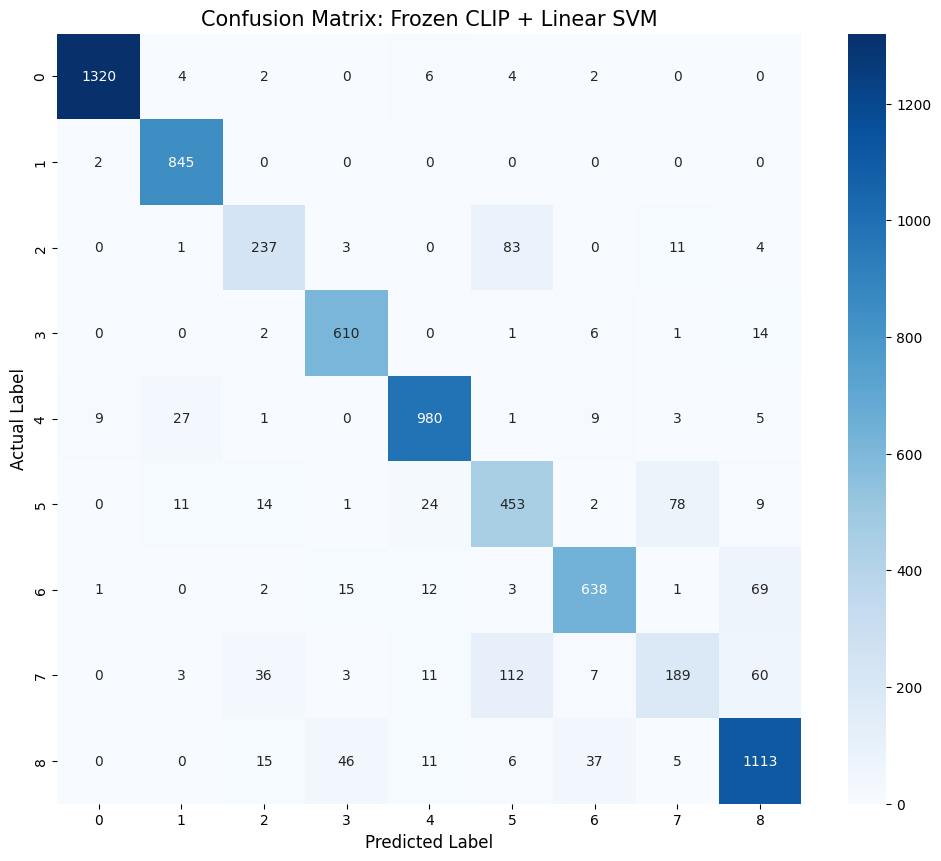

In [4]:
def plot_cm(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(12, 10))
    
    sns.heatmap(
        cm, 
        annot=True, 
        fmt='d', 
        cmap='Blues', 
        cbar=True,
        xticklabels=np.unique(y_true), 
        yticklabels=np.unique(y_true)
    )
    
    plt.title("Confusion Matrix: Frozen CLIP + Linear SVM", fontsize=15)
    plt.ylabel('Actual Label', fontsize=12)
    plt.xlabel('Predicted Label', fontsize=12)
    plt.show()

plot_cm(y_test, y_pred)